# N256: selected-fit comparison across models
Compare **Gaussian, exponential, and stable α = 1.5** side by side. Each figure has panels for `sig2`, `r0`, and `m`, with colors for `sigE`.

Place this notebook in your pipeline root. It uses your existing `py_modules/gstools_fit_viz.py`. No fits are rerun. The loader reads the folder, then selects N256 and the requested models from metadata. N256 means grid side length, not the diagonal `BOX_SIZE`.

Each point is the arithmetic mean over the selected discrete Lfracc values. Bars are the minimum lower to maximum upper posterior endpoints across those fits, **not a combined confidence interval**. Different input length scales, bins, seeds, and source folders are kept in separate figures.

In [1]:
from pathlib import Path
import sys
import importlib
import hashlib
import json
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "py_modules"))
import gstools_fit_viz as gv
gv = importlib.reload(gv)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## Configuration
Use the same fractions for all models for a direct comparison. Optional sample overrides are available below. `None` includes all values for that filter, separated into batches.

In [2]:
FITS_DIR = ROOT / "fits_ready" / "tuned"
GRID_SIZE = 256
MODEL_ORDER = [ "exponential", "stable (alpha=1.5)", "gaussian"]
SIGE_LEVELS = (0, 1, 2)
LENGTH_SCALE = None  # e.g. 16 to compare only N256_L16
SPATIAL_BIN = None
SEED = None
SOURCE_DIR = None

SELECTED_FIT_LIMITS = (0.40, 0.50, 0.60)
REQUIRE_ALL_SELECTED = True
REQUIRE_COMPLETE_COMPARISON = True  # Require all 3 models for every selected sigE
SELECTED_BY_SAMPLE = {
    # Copy exact sample_id values from the inventory below, for example:
    # "gaussian_moments_N256_L16_sigE0": (0.40, 0.50, 0.60),
}

SHOW_REFERENCES = True
REFERENCE_KEYS = {"sig2": "SIG2", "r0": "R0", "m": "M2D"}
PARAM_LABELS = {
    "sig2": r"$\sigma_{\mathrm{pos}}^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pixel]",
    "m": r"$m$",
}
PARAM_YLIMS = None
SAVE_FIGURES = True
SAVE_TABLES = True
FIGURE_FORMATS = ("pdf", "png")

In [3]:
all_results, load_issues = gv.load_results(
    FITS_DIR, recursive=True, reference_keys=REFERENCE_KEYS,
)
if not load_issues.empty:
    display(load_issues)
if all_results.empty:
    raise ValueError(f"No usable fitted files in {FITS_DIR}")

results = gv.filter_results(
    all_results, grid_size=GRID_SIZE, model_label=MODEL_ORDER,
    sigE=SIGE_LEVELS, length_scale=LENGTH_SCALE,
    spatial_bin=SPATIAL_BIN, seed=SEED, source_dir=SOURCE_DIR,
    fit_kind="fraction",
)
if results.empty:
    raise ValueError("No matching fraction fits. Check N256 files and configuration.")
display(gv.inventory(results))
display(gv.fraction_coverage(results, expected=SELECTED_FIT_LIMITS))

,file_name,severity,detail
0,stable_alpha1.5_moments_N128_L16_sigE0_L080.fits,warning,sig2: LM value outside posterior interval; pre...
1,stable_alpha1.5_moments_N128_L16_sigE0_L090.fits,warning,sig2: LM value outside posterior interval; pre...
2,stable_alpha1.5_moments_N128_L16_sigE0_L099.fits,warning,sig2: LM value outside posterior interval; pre...
3,stable_alpha1.5_moments_N128_L16_sigE1_L080.fits,warning,sig2: LM value outside posterior interval; pre...
4,stable_alpha1.5_moments_N128_L16_sigE1_L090.fits,warning,sig2: LM value outside posterior interval; pre...
5,stable_alpha1.5_moments_N128_L16_sigE1_L099.fits,warning,sig2: LM value outside posterior interval; pre...
6,stable_alpha1.5_moments_N128_L16_sigE2_L080.fits,warning,sig2: LM value outside posterior interval; pre...
7,stable_alpha1.5_moments_N128_L16_sigE2_L090.fits,warning,sig2: LM value outside posterior interval; pre...
8,stable_alpha1.5_moments_N128_L16_sigE2_L099.fits,warning,sig2: LM value outside posterior interval; pre...
9,stable_alpha1.5_moments_N64_L16_sigE1_L020.fits,warning,sig2: LM value outside posterior interval; pre...


,sample_id,model_label,sigE,grid_size,length_scale,spatial_bin,seed,fit_kind,fit_limit,relative_uncertainty,fit_model,redchi,n_fit,relative_path
0,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.20,0.022813,bfunc00s,0.958627,29.0,exponential_moments_N256_L16_sigE0_L020.fits
1,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.30,0.022813,bfunc00s,0.872884,32.0,exponential_moments_N256_L16_sigE0_L030.fits
2,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.40,0.022813,bfunc00s,0.861602,35.0,exponential_moments_N256_L16_sigE0_L040.fits
3,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.50,0.052768,bfunc00s,0.908591,37.0,exponential_moments_N256_L16_sigE0_L050.fits
4,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.60,0.060683,bfunc00s,0.836782,38.0,exponential_moments_N256_L16_sigE0_L060.fits
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,stable_alpha1.5_moments_N256_L16_sigE2,stable (alpha=1.5),2.0,256.0,16.0,0,NaN,fraction,0.60,0.069786,bfunc00s,0.979284,38.0,stable_alpha1.5_moments_N256_L16_sigE2_L060.fits
77,stable_alpha1.5_moments_N256_L16_sigE2,stable (alpha=1.5),2.0,256.0,16.0,0,NaN,fraction,0.70,0.069786,bfunc00s,0.970714,40.0,stable_alpha1.5_moments_N256_L16_sigE2_L070.fits
78,stable_alpha1.5_moments_N256_L16_sigE2,stable (alpha=1.5),2.0,256.0,16.0,0,NaN,fraction,0.80,0.080254,bfunc00s,0.764991,41.0,stable_alpha1.5_moments_N256_L16_sigE2_L080.fits
79,stable_alpha1.5_moments_N256_L16_sigE2,stable (alpha=1.5),2.0,256.0,16.0,0,NaN,fraction,0.90,0.080254,bfunc00s,0.829902,42.0,stable_alpha1.5_moments_N256_L16_sigE2_L090.fits


,L040,L050,L060
sample_id,,,
exponential_moments_N256_L16_sigE0,True,True,True
exponential_moments_N256_L16_sigE1,True,True,True
exponential_moments_N256_L16_sigE2,True,True,True
gaussian_moments_N256_L16_sigE0,True,True,True
gaussian_moments_N256_L16_sigE1,True,True,True
gaussian_moments_N256_L16_sigE2,True,True,True
stable_alpha1.5_moments_N256_L16_sigE0,True,True,True
stable_alpha1.5_moments_N256_L16_sigE1,True,True,True
stable_alpha1.5_moments_N256_L16_sigE2,True,True,True


## Selected summaries
After editing fraction choices, rerun from this cell onward. Unknown sample IDs raise an error; valid IDs outside the current selection are reported and ignored.

In [4]:
unknown_samples = set(SELECTED_BY_SAMPLE) - set(all_results["sample_id"])
if unknown_samples:
    raise ValueError("Unknown sample IDs:\n" + "\n".join(sorted(unknown_samples)))
inactive = set(SELECTED_BY_SAMPLE) - set(results["sample_id"])
if inactive:
    print("Overrides outside this comparison (ignored):", sorted(inactive))
active_selection = {k: v for k, v in SELECTED_BY_SAMPLE.items() if k in set(results.sample_id)}
selected_summary, selection_issues = gv.summarize_fractions(
    results, selected=SELECTED_FIT_LIMITS, by_sample=active_selection,
    require_all=REQUIRE_ALL_SELECTED,
)
if not selection_issues.empty:
    display(selection_issues)
if selected_summary.empty:
    raise ValueError("No selected summaries. Review fraction coverage and selections.")
display(selected_summary[[
    "sample_id", "parameter", "fit_limits_used", "n_fractions",
    "value", "interval_low", "interval_high", "fraction_std",
]].sort_values(["sample_id", "parameter"]))

,sample_id,parameter,fit_limits_used,n_fractions,value,interval_low,interval_high,fraction_std
0,exponential_moments_N256_L16_sigE0,m,"(0.4, 0.5, 0.6)",3,1.621410,1.588668,1.671716,0.010308
1,exponential_moments_N256_L16_sigE0,r0,"(0.4, 0.5, 0.6)",3,19.560981,18.360595,20.527114,0.529069
2,exponential_moments_N256_L16_sigE0,sig2,"(0.4, 0.5, 0.6)",3,0.106507,0.100860,0.111425,0.002964
3,exponential_moments_N256_L16_sigE1,m,"(0.4, 0.5, 0.6)",3,1.444767,1.404860,1.492358,0.007851
4,exponential_moments_N256_L16_sigE1,r0,"(0.4, 0.5, 0.6)",3,11.786235,11.227563,12.383817,0.184688
5,exponential_moments_N256_L16_sigE1,sig2,"(0.4, 0.5, 0.6)",3,0.119884,0.116044,0.124002,0.001544
6,exponential_moments_N256_L16_sigE2,m,"(0.4, 0.5, 0.6)",3,1.377003,1.338060,1.429030,0.006682
7,exponential_moments_N256_L16_sigE2,r0,"(0.4, 0.5, 0.6)",3,7.807954,7.490277,8.090869,0.086429
8,exponential_moments_N256_L16_sigE2,sig2,"(0.4, 0.5, 0.6)",3,0.213905,0.208565,0.218803,0.001832
9,gaussian_moments_N256_L16_sigE0,m,"(0.4, 0.5, 0.6)",3,1.981729,1.945354,1.998580,0.001269


,model_label,sigE,fit_limits_used
0,exponential,0.0,"(0.4, 0.5, 0.6)"
1,exponential,1.0,"(0.4, 0.5, 0.6)"
2,exponential,2.0,"(0.4, 0.5, 0.6)"
3,gaussian,0.0,"(0.4, 0.5, 0.6)"
4,gaussian,1.0,"(0.4, 0.5, 0.6)"
5,gaussian,2.0,"(0.4, 0.5, 0.6)"
6,stable (alpha=1.5),0.0,"(0.4, 0.5, 0.6)"
7,stable (alpha=1.5),1.0,"(0.4, 0.5, 0.6)"
8,stable (alpha=1.5),2.0,"(0.4, 0.5, 0.6)"


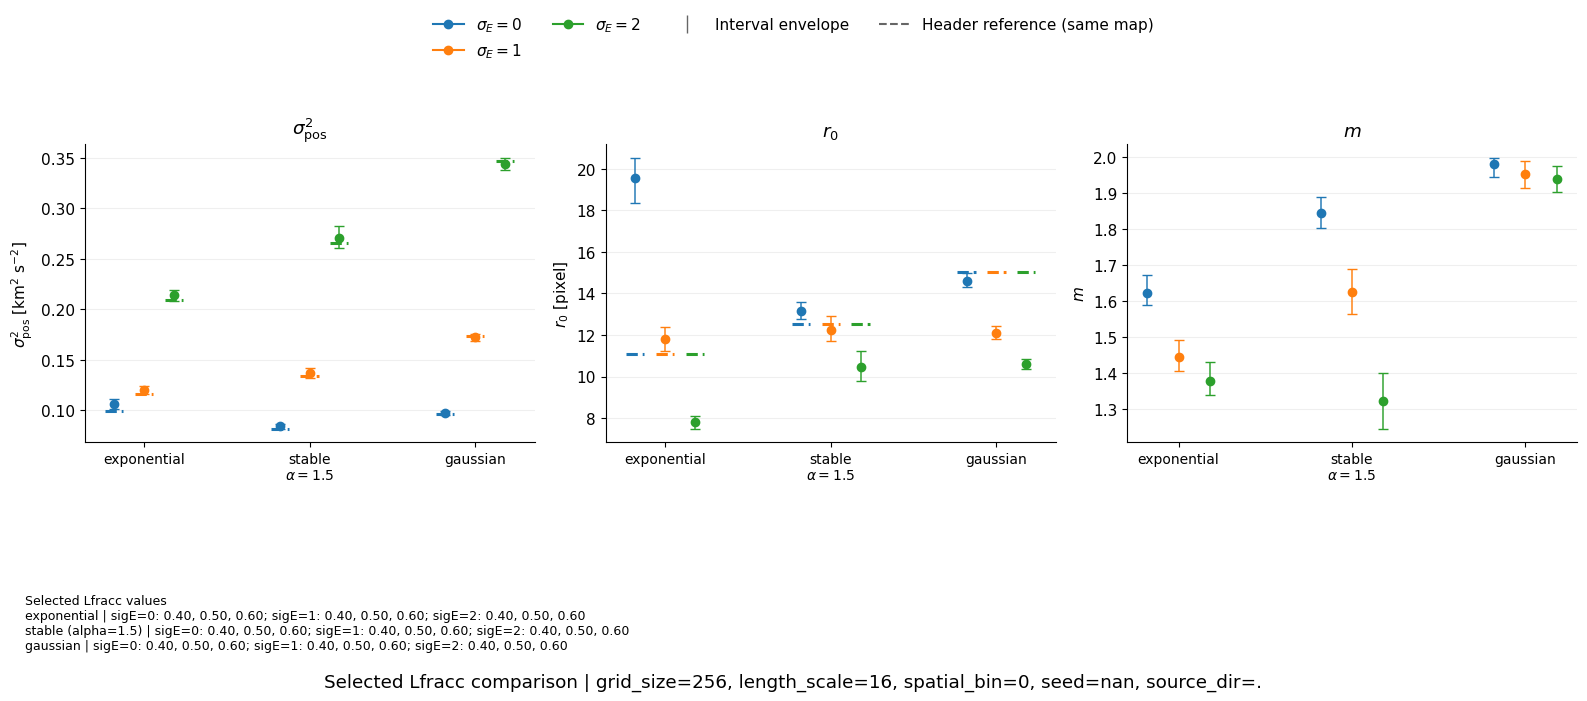

Figure destination: C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\fit_results\N256_gaussian_exponential_stable15_d1fb089f73
Table destination: C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\results_fit\visualization\N256_gaussian_exponential_stable15_d1fb089f73


In [5]:
# Model names and a configuration fingerprint keep different selections separate.
config = dict(grid=GRID_SIZE, models=MODEL_ORDER, sigE=SIGE_LEVELS,
              length=LENGTH_SCALE, bin=SPATIAL_BIN, seed=SEED, source=SOURCE_DIR,
              fits_dir=str(FITS_DIR.resolve()), fractions=SELECTED_FIT_LIMITS,
              overrides=active_selection, require_all=REQUIRE_ALL_SELECTED,
              references=SHOW_REFERENCES, reference_keys=REFERENCE_KEYS,
              ylims=PARAM_YLIMS)
fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:10]
RUN_TAG = f"N{GRID_SIZE}_gaussian_exponential_stable15_{fingerprint}"
FIGS_DIR = ROOT / "Imgs" / "fit_results" / RUN_TAG
TABLES_DIR = ROOT / "results_fit" / "visualization" / RUN_TAG
BATCH_KEYS = (*gv.BATCH_KEYS, "source_dir")

# Validate before plotting so incomplete comparisons are not silently presented.
batches = list(gv.iter_batches(selected_summary, keys=BATCH_KEYS))
expected = {(model, float(level), parameter)
            for model in MODEL_ORDER for level in SIGE_LEVELS
            for parameter in ("sig2", "r0", "m")}
for batch_title, batch in batches:
    if batch.duplicated(["model_label", "sigE", "parameter"]).any():
        raise ValueError(f"Multiple samples per model/sigE in {batch_title}; narrow the filters.")
    present = set(zip(batch.model_label, batch.sigE.astype(float), batch.parameter))
    missing = expected - present
    if missing:
        message = f"Missing model/sigE/parameter combinations in {batch_title}: {sorted(missing)}"
        if REQUIRE_COMPLETE_COMPARISON:
            raise ValueError(message)
        print(message)

for batch_index, (batch_title, batch) in enumerate(batches):
    selections = batch[["model_label", "sigE", "fit_limits_used"]].drop_duplicates()
    display(selections.reset_index(drop=True))
    fig, axes = gv.plot_parameters(
        batch, model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
        reference=SHOW_REFERENCES, labels=PARAM_LABELS, ylims=PARAM_YLIMS,
        title=f"Selected Lfracc comparison | {batch_title}",
    )
    # Put the actual selections in the figure, not only in the notebook table.
    lines = []
    for model in MODEL_ORDER:
        rows = selections.loc[selections.model_label == model].sort_values("sigE")
        entries = [f"sigE={row.sigE:g}: " + ", ".join(f"{x:.2f}" for x in row.fit_limits_used)
                   for row in rows.itertuples()]
        if entries:
            lines.append(model + " | " + "; ".join(entries))
    fig.set_size_inches(16, 7)
    fig.tight_layout(rect=(0, 0.24, 1, 0.86))
    fig.text(0.02, 0.07, "Selected Lfracc values\n" + "\n".join(lines),
             ha="left", va="bottom", fontsize=9)
    if SAVE_FIGURES:
        gv.save_figure(fig, FIGS_DIR,
                       f"selected_parameters_{RUN_TAG}_{batch_index}",
                       formats=FIGURE_FORMATS)
    plt.show()
    plt.close(fig)

if SAVE_TABLES:
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    selected_summary.to_csv(TABLES_DIR / f"selected_summary_{RUN_TAG}.csv", index=False)
    selection_issues.to_csv(TABLES_DIR / "selection_issues.csv", index=False)
    (TABLES_DIR / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Figure destination:", FIGS_DIR)
print("Table destination:", TABLES_DIR)